In [1]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_pmf, set_style

# Apply standard style across all plots
set_style()

# Poisson Distribution: Modeling Event Counts Over Time and Space

## 1. Intuition & Motivation

In the Binomial distribution, we knew the exact number of trials $n$ (e.g., flip a coin 10 times).
However, many real-world processes do not have a fixed $n$:
- How many customer support calls arrive at a call center between 2:00 PM and 3:00 PM?
- How many HTTP requests hit a web server each second?
- How many potholes exist per kilometer of highway?
- How many radioactive particles decay per minute?

In these cases, events occur continuously and independently at a known average rate, called **$\lambda$ (lambda)**.

The **Poisson distribution** models the number of times an event occurs within a fixed interval of time, distance, area, or volume. It is often called the **Law of Rare Events** because it naturally arises when there are countless opportunities for an event to happen, but the probability of it occurring at any single instant is extremely small.

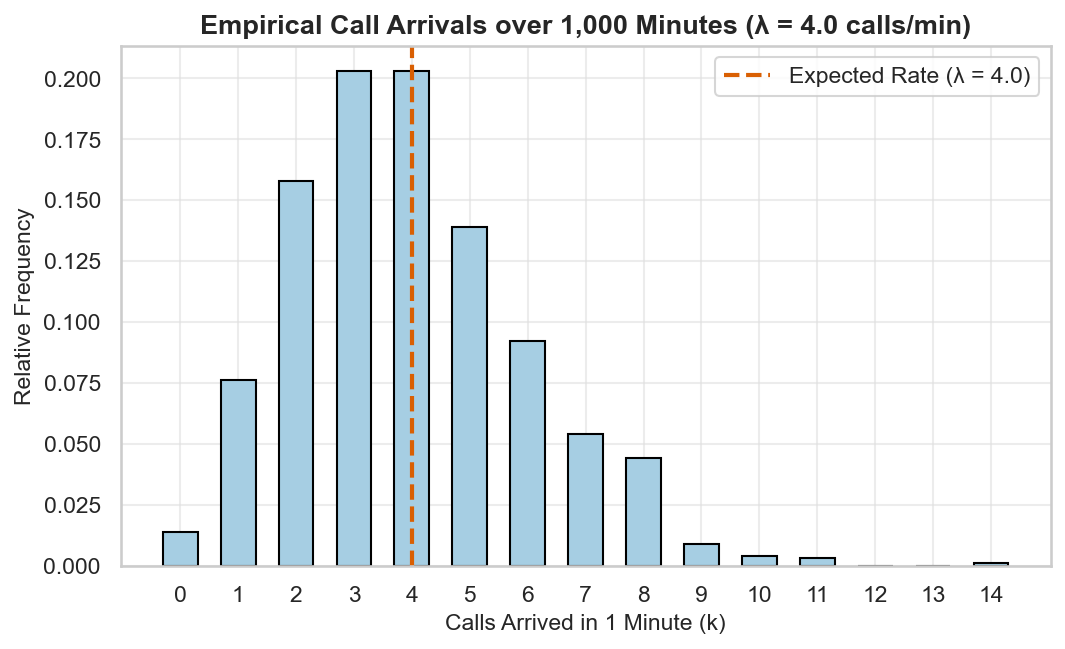

Sample Mean Calls/Min: 3.958
Sample Var Calls/Min:  4.058


In [2]:
# Average arrival rate: lambda = 4 calls per minute
lam_calls = 4.0
n_minutes = 1000

# Seed for reproducibility
rng = np.random.default_rng(seed=42)

# Simulate call arrivals across 1,000 one-minute intervals
simulated_calls = rng.poisson(lam=lam_calls, size=n_minutes)

# Plot empirical distribution
max_observed = max(simulated_calls)
counts, bins = np.histogram(
    simulated_calls, bins=np.arange(-0.5, max_observed + 1.5, 1)
)

plt.figure(figsize=(8, 4.5))
plt.bar(
    np.arange(0, max_observed + 1),
    counts / n_minutes,
    color=PALETTE["fill"],
    edgecolor="black",
    width=0.6,
)
plt.axvline(
    lam_calls,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Expected Rate (λ = {lam_calls})",
)

plt.title(
    f"Empirical Call Arrivals over 1,000 Minutes (λ = {lam_calls} calls/min)"
)
plt.xlabel("Calls Arrived in 1 Minute (k)")
plt.ylabel("Relative Frequency")
plt.xticks(range(0, max_observed + 1))
plt.legend(frameon=True)
plt.show()

print(f"Sample Mean Calls/Min: {np.mean(simulated_calls):.3f}")
print(f"Sample Var Calls/Min:  {np.var(simulated_calls, ddof=1):.3f}")

## 2. Mathematical Definition

A discrete random variable $X$ follows a Poisson distribution with rate parameter $\lambda$, written:
$$X \sim \text{Poisson}(\lambda)$$

### Parameter & Support
- **$\lambda > 0$ (lambda)**: Expected number of occurrences per fixed interval (the arrival rate).
- **Support**: All non-negative integers: $k \in \{0, 1, 2, 3, \dots\}$.

### Probability Mass Function (PMF)
The probability of observing exactly $k$ events in the interval is:
$$P(X = k) = \frac{\lambda^k e^{-\lambda}}{k!} \quad \text{for } k = 0, 1, 2, \dots$$

*(Note: The probabilities sum to $1$ because $\sum_{k=0}^\infty \frac{\lambda^k}{k!} = e^\lambda$, so $\sum_{k=0}^\infty P(X = k) = e^{-\lambda} \cdot e^{\lambda} = 1$.)*

### Cumulative Distribution Function (CDF)
The probability of observing at most $k$ events:
$$F(k) = P(X \le k) = \sum_{i=0}^{\lfloor k \rfloor} \frac{\lambda^i e^{-\lambda}}{i!} = e^{-\lambda} \sum_{i=0}^{\lfloor k \rfloor} \frac{\lambda^i}{i!}$$

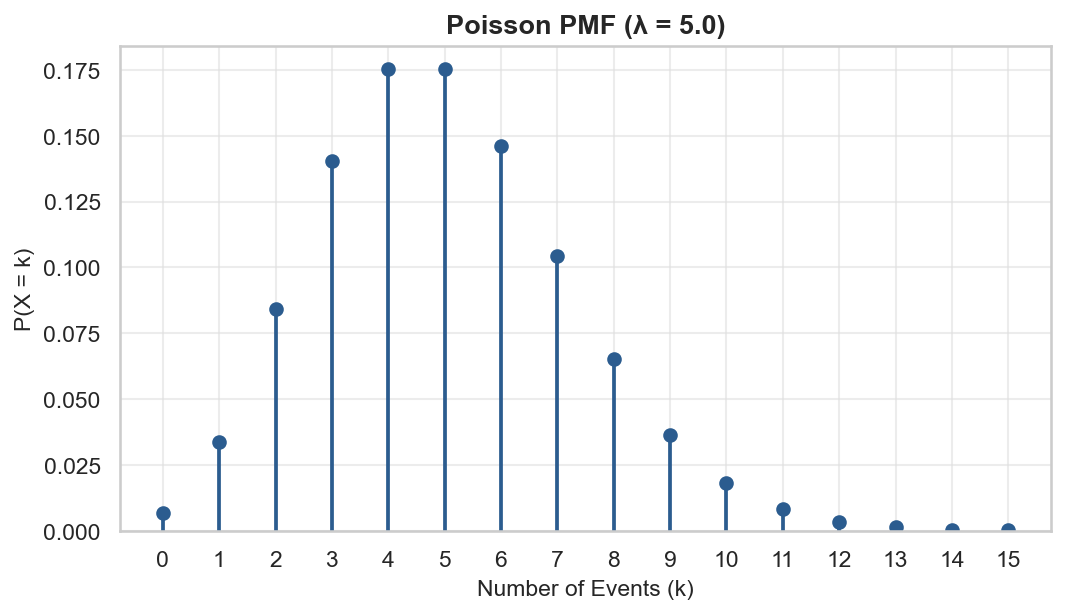

In [3]:
# Rate parameter
lam = 5.0

# Support values to visualize (0 up to 3*lambda)
k_values = np.arange(0, int(3 * lam) + 1)

# Evaluate exact theoretical PMF: P(X = k)
pmf_values = stats.poisson.pmf(k_values, lam)

# Plot PMF using our shared helper
fig, ax = plt.subplots(figsize=(8, 4.2))
plot_pmf(
    k_values,
    pmf_values,
    title=f"Poisson PMF (λ = {lam})",
    xlabel="Number of Events (k)",
    ylabel="P(X = k)",
    ax=ax,
)
ax.set_xticks(k_values)
plt.show()

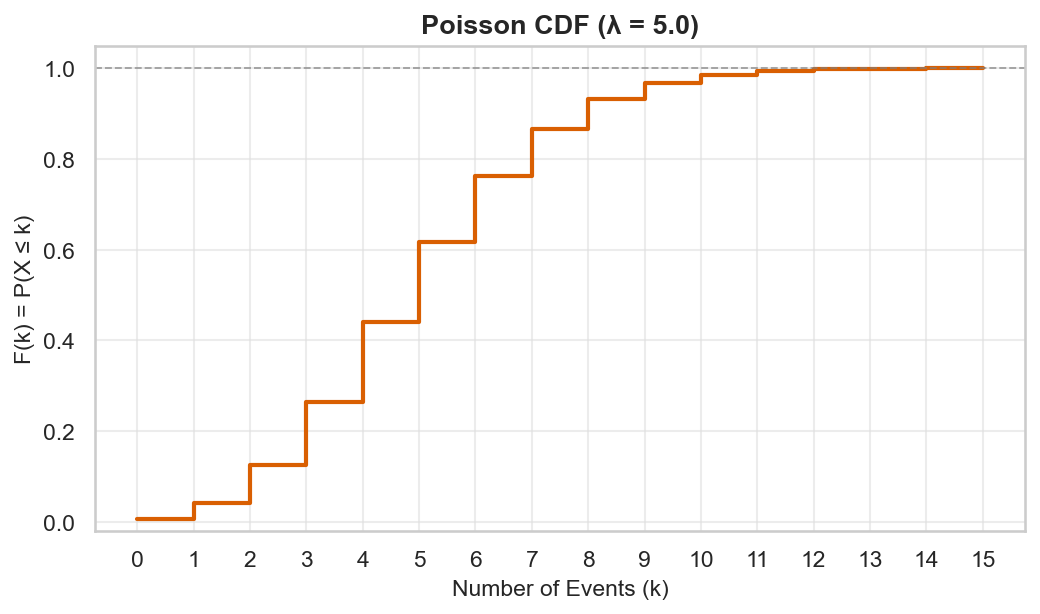

In [4]:
from utils.plotting import plot_cdf

# Evaluate theoretical CDF: P(X <= k)
cdf_values = stats.poisson.cdf(k_values, lam)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cdf(
    k_values,
    cdf_values,
    is_discrete=True,
    title=f"Poisson CDF (λ = {lam})",
    xlabel="Number of Events (k)",
    ylabel="F(k) = P(X ≤ k)",
    ax=ax,
)
ax.set_xticks(k_values)
plt.show()

## 3. Key Theoretical Properties

The Poisson distribution is uniquely governed by a single parameter $\lambda$, leading to special mathematical properties:

### 1. Expected Value (Mean): $\mathbb{E}[X] = \mu$
$$\mu = \lambda$$

### 2. Variance & Standard Deviation: $\text{Var}(X) = \sigma^2$
$$\sigma^2 = \lambda, \quad \sigma = \sqrt{\lambda}$$

> **Key Concept — Equidispersion:**
> In a Poisson distribution, the variance is **strictly equal to the mean** ($\sigma^2 = \mu = \lambda$).
> - If observed data has $\text{Var}(X) > \mathbb{E}[X]$, it is called **overdispersed** (common in real-world data, requiring a Negative Binomial model).
> - If $\text{Var}(X) < \mathbb{E}[X]$, it is called **underdispersed**.

### 3. Skewness: $\gamma_1$
$$\gamma_1 = \frac{1}{\sqrt{\lambda}}$$
Skewness is strictly positive ($\gamma_1 > 0$), meaning the distribution always has a right tail. However, as $\lambda \to \infty$, $\gamma_1 \to 0$ (it becomes symmetric and bell-shaped).

### 4. Excess Kurtosis: $\gamma_2$
$$\gamma_2 = \frac{1}{\lambda}$$
As $\lambda \to \infty$, $\gamma_2 \to 0$, converging to the kurtosis of a Normal distribution.

In [6]:
# Parameter
lam_test = 6.25  # Chosen so sqrt(lam) = 2.5 is clean

# Analytical formulas
mu_formula = lam_test
var_formula = lam_test
std_formula = np.sqrt(var_formula)
skew_formula = 1.0 / np.sqrt(lam_test)
kurt_formula = 1.0 / lam_test

# SciPy calculation
mu_sp, var_sp, skew_sp, kurt_sp = stats.poisson.stats(lam_test, moments="mvsk")

print("--- POISSON THEORETICAL MOMENTS ---")
print(f"Moment               | Analytical |    SciPy")
print("-" * 46)
print(f"Mean (μ)             | {mu_formula:10.4f} | {float(mu_sp):10.4f}")
print(f"Variance (σ²)        | {var_formula:10.4f} | {float(var_sp):10.4f}")
print(f"Std Deviation (σ)    | {std_formula:10.4f} | {np.sqrt(float(var_sp)):10.4f}")
print(f"Skewness (γ₁)        | {skew_formula:10.4f} | {float(skew_sp):10.4f}")
print(f"Excess Kurtosis (γ₂) | {kurt_formula:10.4f} | {float(kurt_sp):10.4f}")

--- POISSON THEORETICAL MOMENTS ---
Moment               | Analytical |    SciPy
----------------------------------------------
Mean (μ)             |     6.2500 |     6.2500
Variance (σ²)        |     6.2500 |     6.2500
Std Deviation (σ)    |     2.5000 |     2.5000
Skewness (γ₁)        |     0.4000 |     0.4000
Excess Kurtosis (γ₂) |     0.1600 |     0.1600


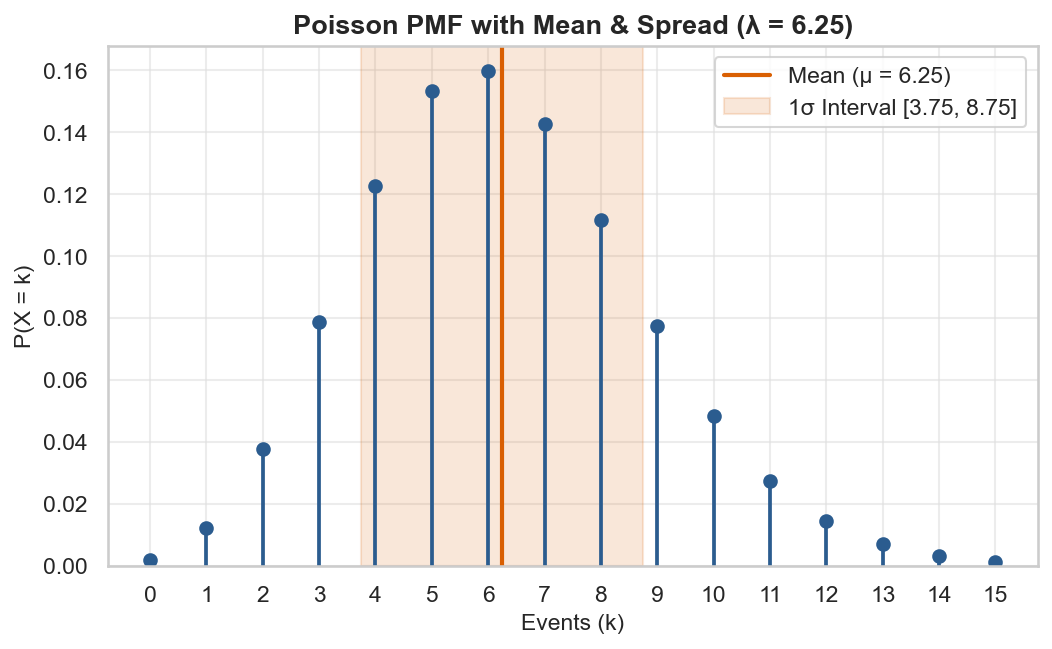

In [7]:
k_eval = np.arange(0, 16)
pmf_eval = stats.poisson.pmf(k_eval, lam_test)

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_pmf(
    k_eval,
    pmf_eval,
    title=f"Poisson PMF with Mean & Spread (λ = {lam_test})",
    xlabel="Events (k)",
    ylabel="P(X = k)",
    ax=ax,
)

# Overlay Mean and 1-Sigma Band
ax.axvline(
    mu_formula,
    color=PALETTE["secondary"],
    linestyle="-",
    linewidth=2,
    label=f"Mean (μ = {mu_formula:.2f})",
)
ax.axvspan(
    mu_formula - std_formula,
    mu_formula + std_formula,
    color=PALETTE["secondary"],
    alpha=0.15,
    label=f"1σ Interval [{mu_formula - std_formula:.2f}, {mu_formula + std_formula:.2f}]",
)

ax.set_xticks(k_eval)
ax.legend(frameon=True)
plt.show()

## 4. Parameter Variation

Because $\lambda$ is both the mean and the variance, changing $\lambda$ fundamentally alters the distribution's location, spread, and shape:

1. **Low Rate ($\lambda \le 1$, e.g., $\lambda = 0.8$ or $1$)**:
   - The mode is at $k = 0$ or $k = 1$.
   - Strongly right-skewed with high concentration near zero.
2. **Moderate Rate ($\lambda = 4$ to $10$)**:
   - The distribution detaches from zero and forms a distinct unimodal hump peaked at $\lfloor \lambda \rfloor$.
   - Right tail is still noticeably longer than the left tail.
3. **High Rate ($\lambda \ge 15$ to $20$)**:
   - Skewness decays towards zero ($\gamma_1 = 1/\sqrt{\lambda} \to 0$).
   - The discrete distribution becomes remarkably symmetric, closely mirroring a continuous Normal distribution $\mathcal{N}(\lambda, \lambda)$.

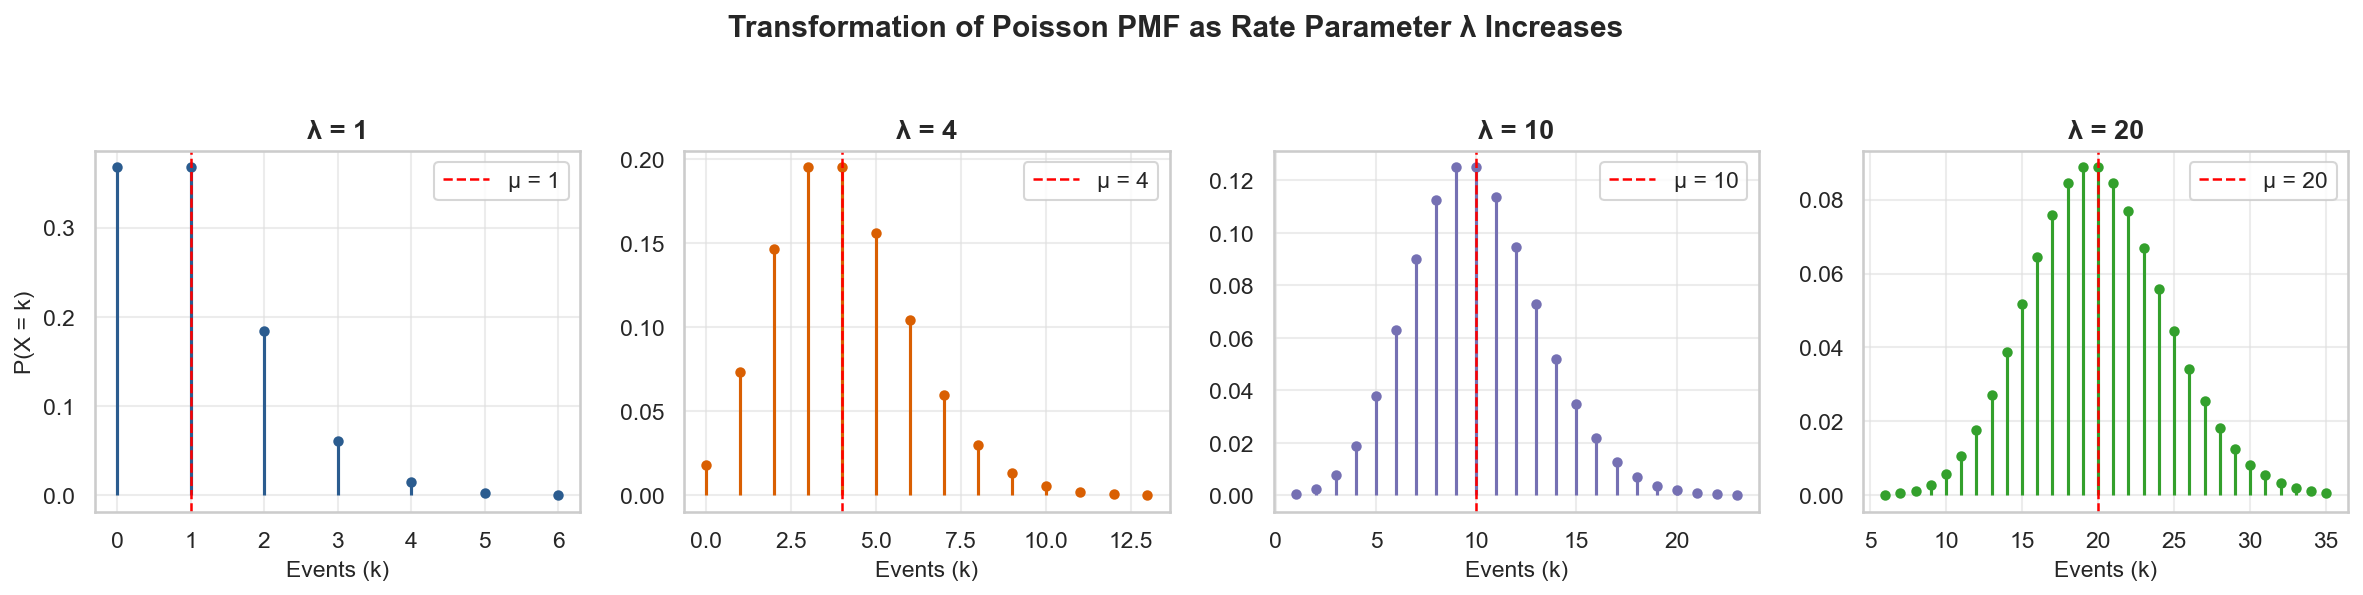

In [8]:
lambdas = [1, 4, 10, 20]
colors = [
    PALETTE["primary"],
    PALETTE["secondary"],
    PALETTE["accent"],
    "#33a02c",
]
k_max_plot = 35
k_axis = np.arange(0, k_max_plot + 1)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=False)

for ax, lam_val, col in zip(axes, lambdas, colors):
    pmf = stats.poisson.pmf(k_axis, lam_val)
    # Only plot where probability is non-negligible
    mask = pmf > 1e-4
    markerline, stemlines, _ = ax.stem(
        k_axis[mask], pmf[mask], basefmt=" "
    )
    plt.setp(markerline, color=col, markersize=4)
    plt.setp(stemlines, color=col, linewidth=1.5)

    ax.axvline(
        lam_val,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label=f"μ = {lam_val}",
    )
    ax.set_title(f"λ = {lam_val}", weight="bold")
    ax.set_xlabel("Events (k)")
    ax.legend(frameon=True, loc="upper right")

axes[0].set_ylabel("P(X = k)")
plt.suptitle(
    "Transformation of Poisson PMF as Rate Parameter λ Increases",
    y=1.04,
    weight="bold",
)
plt.tight_layout()
plt.show()

## 5. Simulation & Law of Large Numbers

When we simulate $N$ independent draws $X_1, X_2, \dots, X_N \sim \text{Poisson}(\lambda)$:
1. **Convergence of the Mean**: By the Law of Large Numbers:
   $$\bar{X}_N = \frac{1}{N}\sum_{i=1}^{N} X_i \xrightarrow{P} \lambda$$
2. **Convergence of the Variance (Equidispersion)**: The sample variance also converges to $\lambda$:
   $$s^2_N = \frac{1}{N-1}\sum_{i=1}^{N} (X_i - \bar{X}_N)^2 \xrightarrow{P} \lambda$$

Tracking both running metrics simultaneously provides a clear visual demonstration of Poisson equidispersion in action.

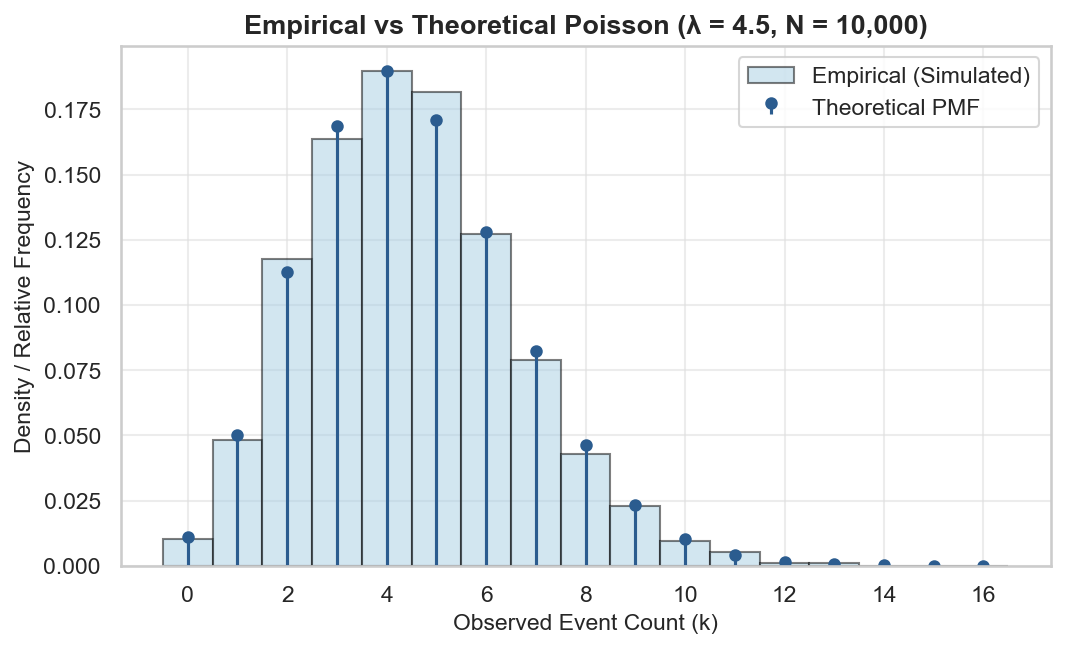

Theoretical λ:    4.5000
Sample Mean (x̄):  4.4914
Sample Var (s²):  4.4400


In [9]:
from utils.plotting import plot_sample_vs_theory

# Parameters
lam_sim = 4.5
sample_size = 10000

# Generate pseudo-random Poisson variates
samples = stats.poisson.rvs(lam_sim, size=sample_size, random_state=42)

# Theoretical PMF coordinates
k_max = int(np.max(samples))
k_theory = np.arange(0, k_max + 1)
pmf_theory = stats.poisson.pmf(k_theory, lam_sim)

# Plot empirical histogram vs theoretical stems
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_sample_vs_theory(
    samples=samples,
    x_theory=k_theory,
    y_theory=pmf_theory,
    is_discrete=True,
    title=f"Empirical vs Theoretical Poisson (λ = {lam_sim}, N = {sample_size:,})",
    xlabel="Observed Event Count (k)",
    ax=ax,
)
ax.set_xticks(range(0, k_max + 1, 2))
plt.show()

# Verification metrics
print(f"Theoretical λ:    {lam_sim:.4f}")
print(f"Sample Mean (x̄):  {np.mean(samples):.4f}")
print(f"Sample Var (s²):  {np.var(samples, ddof=1):.4f}")

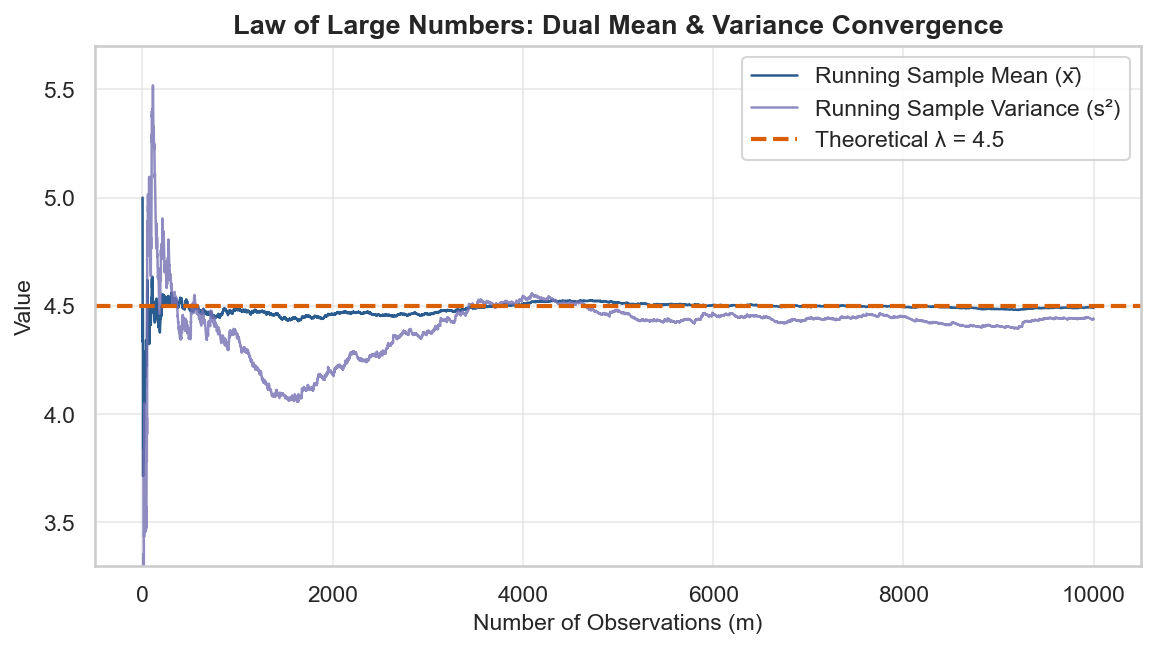

In [18]:
# Compute running sample mean
m_indices = np.arange(1, sample_size + 1)
running_mean = np.cumsum(samples) / m_indices

# Compute running sample variance using the identity: Var = E[X^2] - (E[X])^2
running_mean_sq = np.cumsum(samples**2) / m_indices
running_var = (running_mean_sq - running_mean**2) * (m_indices / np.maximum(1, m_indices - 1))

plt.figure(figsize=(9, 4.5))
plt.plot(
    m_indices,
    running_mean,
    color=PALETTE["primary"],
    linewidth=1.2,
    label="Running Sample Mean (x̄)",
)
plt.plot(
    m_indices,
    running_var,
    color=PALETTE["accent"],
    linewidth=1.2,
    alpha=0.8,
    label="Running Sample Variance (s²)",
)
plt.axhline(
    lam_sim,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical λ = {lam_sim}",
)

plt.title("Law of Large Numbers: Dual Mean & Variance Convergence")
plt.xlabel("Number of Observations (m)")
plt.ylabel("Value")
plt.ylim(lam_sim - 1.2, lam_sim + 1.2)
plt.legend(frameon=True)
plt.show()

## 6. Applied Real-World Use Case: Server Capacity & Anomaly Detection

### Scenario
A cloud microservice receives an average of **$\lambda = 12$ requests per second (RPS)** under normal conditions:
$$X \sim \text{Poisson}(\lambda = 12)$$

### Infrastructure Constraints:
- A single baseline server container is provisioned to process up to **$C = 18$ RPS** without latency degradation.
- If traffic exceeds $18$ RPS in a given second, the excess requests queue up and auto-scaling should spin up a secondary container.
- If traffic exceeds a critical threshold $k^*$, where the probability under normal operation is less than $1$ in $10,000$ seconds ($P(X \ge k^*) < 10^{-4}$), an automated high-priority pager alert must fire to investigate a DDoS attack or runaway client.

### Engineering Questions:
1. What percentage of seconds will the single container handle without needing auto-scaling?
2. What is the probability of a burst overload ($P(X > 18)$)?
3. What is the exact request count $k^*$ that should trigger a DDoS alert?

In [19]:
lam_rps = 12.0
capacity = 18

# 1. P(Handled safely by single container): P(X <= 18)
prob_safe = stats.poisson.cdf(capacity, lam_rps)

# 2. P(Auto-scale spillover): P(X > 18)
prob_spillover = stats.poisson.sf(capacity, lam_rps)

# 3. Critical threshold for DDoS / runaway traffic: 99.99th percentile
alert_percentile = 0.9999
alert_threshold = int(stats.poisson.ppf(alert_percentile, lam_rps))
prob_alert = stats.poisson.sf(alert_threshold - 1, lam_rps)

print("--- CLOUD SERVER CAPACITY ANALYSIS ---")
print(f"Average Traffic Rate:        {lam_rps:.1f} RPS")
print(f"Single Container Capacity:   {capacity} RPS\n")
print(f"Safe Operating Seconds:      {prob_safe * 100:.2f}%")
print(f"Spillover / Scale-Up Seconds: {prob_spillover * 100:.2f}% (approx 1 every {int(1/prob_spillover)} seconds)")
print(f"\n--- ANOMALY ALERT THRESHOLD ---")
print(f"Alert Threshold (99.99%):    >= {alert_threshold} RPS")
print(f"False Alarm Rate per Second: {prob_alert:.2e} (approx 1 false alarm every {int(1/prob_alert)/3600:.1f} hours)")

--- CLOUD SERVER CAPACITY ANALYSIS ---
Average Traffic Rate:        12.0 RPS
Single Container Capacity:   18 RPS

Safe Operating Seconds:      96.26%
Spillover / Scale-Up Seconds: 3.74% (approx 1 every 26 seconds)

--- ANOMALY ALERT THRESHOLD ---
Alert Threshold (99.99%):    >= 27 RPS
False Alarm Rate per Second: 1.33e-04 (approx 1 false alarm every 2.1 hours)


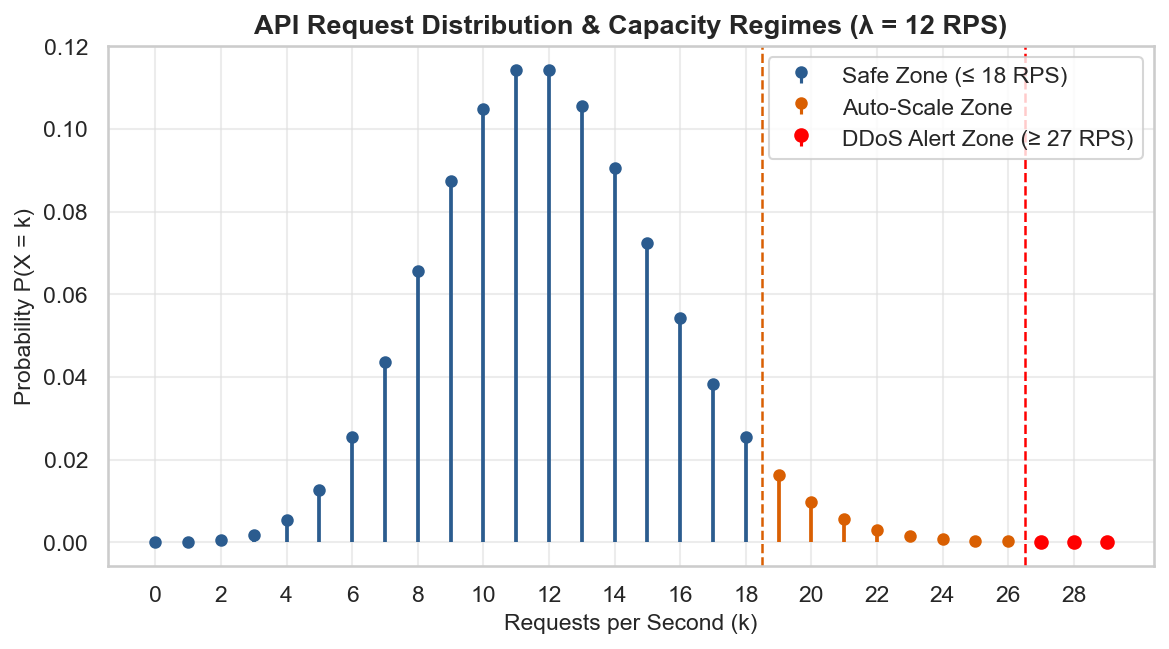

In [20]:
k_range = np.arange(0, 30)
pmf_workload = stats.poisson.pmf(k_range, lam_rps)

fig, ax = plt.subplots(figsize=(9, 4.5))

# Region 1: Safe operating load (k <= 18)
mask_safe = k_range <= capacity
marker_s, stem_s, _ = ax.stem(
    k_range[mask_safe], pmf_workload[mask_safe], basefmt=" ", label=f"Safe Zone (≤ {capacity} RPS)"
)
plt.setp(marker_s, color=PALETTE["primary"], markersize=5)
plt.setp(stem_s, color=PALETTE["primary"], linewidth=1.8)

# Region 2: Auto-scale spillover (19 <= k < alert_threshold)
mask_scale = (k_range > capacity) & (k_range < alert_threshold)
marker_sc, stem_sc, _ = ax.stem(
    k_range[mask_scale], pmf_workload[mask_scale], basefmt=" ", label="Auto-Scale Zone"
)
plt.setp(marker_sc, color=PALETTE["secondary"], markersize=5)
plt.setp(stem_sc, color=PALETTE["secondary"], linewidth=1.8)

# Region 3: Critical incident / DDoS zone (k >= alert_threshold)
mask_alert = k_range >= alert_threshold
marker_al, stem_al, _ = ax.stem(
    k_range[mask_alert], pmf_workload[mask_alert], basefmt=" ", label=f"DDoS Alert Zone (≥ {alert_threshold} RPS)"
)
plt.setp(marker_al, color="red", markersize=6)
plt.setp(stem_al, color="red", linewidth=2)

# Boundary lines
ax.axvline(capacity + 0.5, color=PALETTE["secondary"], linestyle="--", linewidth=1.2)
ax.axvline(alert_threshold - 0.5, color="red", linestyle="--", linewidth=1.2)

ax.set_title("API Request Distribution & Capacity Regimes (λ = 12 RPS)", weight="bold")
ax.set_xlabel("Requests per Second (k)")
ax.set_ylabel("Probability P(X = k)")
ax.set_xticks(range(0, 30, 2))
ax.legend(frameon=True)
plt.show()

## 7. Parameter Estimation (Maximum Likelihood Estimation - MLE)

Given a sample of $N$ count observations $k_1, k_2, \dots, k_N$, how do we estimate the unknown rate parameter $\lambda$?

### The Likelihood Function
The joint probability of observing our exact sample is:
$$L(\lambda) = \prod_{i=1}^{N} \frac{\lambda^{k_i} e^{-\lambda}}{k_i!} = \frac{\lambda^{\sum k_i} e^{-N\lambda}}{\prod_{i=1}^N k_i!}$$

### Log-Likelihood & Optimization
Taking the natural logarithm:
$$\ln L(\lambda) = \left(\sum_{i=1}^{N} k_i\right) \ln(\lambda) - N\lambda - \sum_{i=1}^{N} \ln(k_i!)$$

Differentiating with respect to $\lambda$ and setting the derivative to zero:
$$\frac{d}{d\lambda} \ln L(\lambda) = \frac{\sum k_i}{\lambda} - N = 0$$

Solving for $\lambda$ yields the **analytical MLE**:
$$\hat{\lambda}_{\text{MLE}} = \frac{1}{N} \sum_{i=1}^{N} k_i = \bar{k}$$
The Maximum Likelihood Estimate of the Poisson rate is simply the **sample mean**!

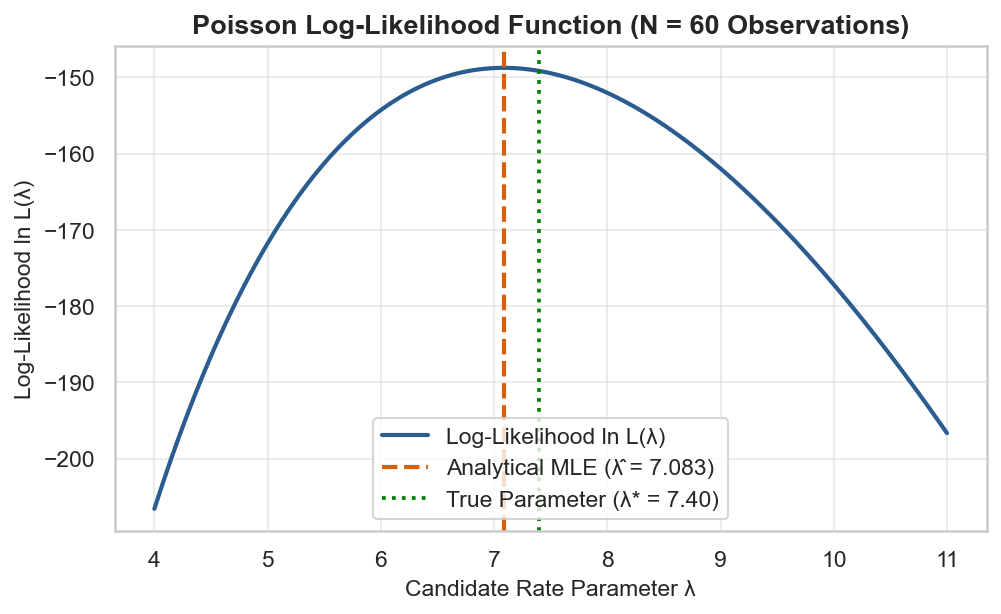

In [21]:
# True underlying rate parameter
lam_true = 7.4
N_obs = 60

# Generate synthetic count observations
obs_counts = stats.poisson.rvs(lam_true, size=N_obs, random_state=88)

# Analytical MLE: sample mean
lam_mle_analytical = np.mean(obs_counts)


# Poisson log-likelihood function
def poisson_log_lik(lam_candidates, data):
    n = len(data)
    sum_k = np.sum(data)
    # Sum of log-pmf across observations
    return np.array([np.sum(stats.poisson.logpmf(data, l_val)) for l_val in lam_candidates])


lam_grid = np.linspace(4.0, 11.0, 300)
log_lik_values = poisson_log_lik(lam_grid, obs_counts)

# Plot Log-Likelihood Curve
plt.figure(figsize=(7.5, 4.2))
plt.plot(
    lam_grid,
    log_lik_values,
    color=PALETTE["primary"],
    linewidth=2,
    label="Log-Likelihood ln L(λ)",
)
plt.axvline(
    lam_mle_analytical,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Analytical MLE (λ̂ = {lam_mle_analytical:.3f})",
)
plt.axvline(
    lam_true,
    color="green",
    linestyle=":",
    linewidth=1.8,
    label=f"True Parameter (λ* = {lam_true:.2f})",
)

plt.title(f"Poisson Log-Likelihood Function (N = {N_obs} Observations)")
plt.xlabel("Candidate Rate Parameter λ")
plt.ylabel("Log-Likelihood ln L(λ)")
plt.legend(frameon=True)
plt.show()

In [22]:
from scipy.optimize import minimize


# Negative log-likelihood objective function
def neg_poisson_log_lik(lam, data):
    l_val = np.clip(lam[0], 1e-4, 1e4)
    return -np.sum(stats.poisson.logpmf(data, l_val))


# Minimize NLL starting from guess 1.0
res = minimize(
    neg_poisson_log_lik, x0=[1.0], args=(obs_counts,), bounds=[(1e-3, 100.0)]
)
lam_mle_num = res.x[0]

# Standard Error from Fisher Information: SE = sqrt(lambda / N)
se_mle = np.sqrt(lam_mle_num / N_obs)
ci_lower = lam_mle_num - 1.96 * se_mle
ci_upper = lam_mle_num + 1.96 * se_mle

print("--- POISSON MLE ESTIMATION RESULTS ---")
print(f"True Parameter (λ*):        {lam_true:.4f}")
print(f"Analytical MLE (x̄):         {lam_mle_analytical:.4f}")
print(f"Numerical MLE (Optimizer):  {lam_mle_num:.4f}")
print(f"Standard Error (SE):        {se_mle:.4f}")
print(f"95% Confidence Interval:    [{ci_lower:.4f}, {ci_upper:.4f}]")

--- POISSON MLE ESTIMATION RESULTS ---
True Parameter (λ*):        7.4000
Analytical MLE (x̄):         7.0833
Numerical MLE (Optimizer):  7.0833
Standard Error (SE):        0.3436
95% Confidence Interval:    [6.4099, 7.7568]


## 8. Related Distributions & Summary

The Poisson distribution is one of the most connected distributions in probability:

1. **Binomial Distribution (Law of Rare Events)**:
   - Poisson is the limit of the Binomial distribution as $n \to \infty$ and $p \to 0$ with $n p = \lambda$:
     $$\lim_{n \to \infty, p \to 0} \binom{n}{k} p^k (1 - p)^{n - k} = \frac{\lambda^k e^{-\lambda}}{k!}$$
2. **Exponential Distribution (Inter-Arrival Times)**:
   - If events occur as a Poisson process with rate $\lambda$, the waiting time $T$ between consecutive arrivals follows an **Exponential distribution**:
     $$T \sim \text{Exponential}\left(\text{rate} = \lambda, \, \text{scale} = \frac{1}{\lambda}\right)$$
3. **Gamma Distribution (Waiting for $k$ Events & Bayesian Prior)**:
   - The time required to observe $k$ Poisson arrivals follows a $\text{Gamma}(k, \lambda)$ distribution.
   - The Gamma distribution is also the **conjugate prior** for the Poisson rate parameter $\lambda$ in Bayesian statistics.
4. **Normal Distribution (Central Limit Theorem)**:
   - For $\lambda \ge 15$, the Poisson distribution is closely approximated by a Normal distribution:
     $$\text{Poisson}(\lambda) \approx \mathcal{N}(\mu = \lambda, \, \sigma^2 = \lambda)$$
5. **Negative Binomial Distribution (Poisson-Gamma Mixture)**:
   - When the underlying rate $\lambda$ is not constant but varies randomly according to a Gamma distribution across observations, the resulting marginal distribution is **Negative Binomial** (which accommodates overdispersion!).

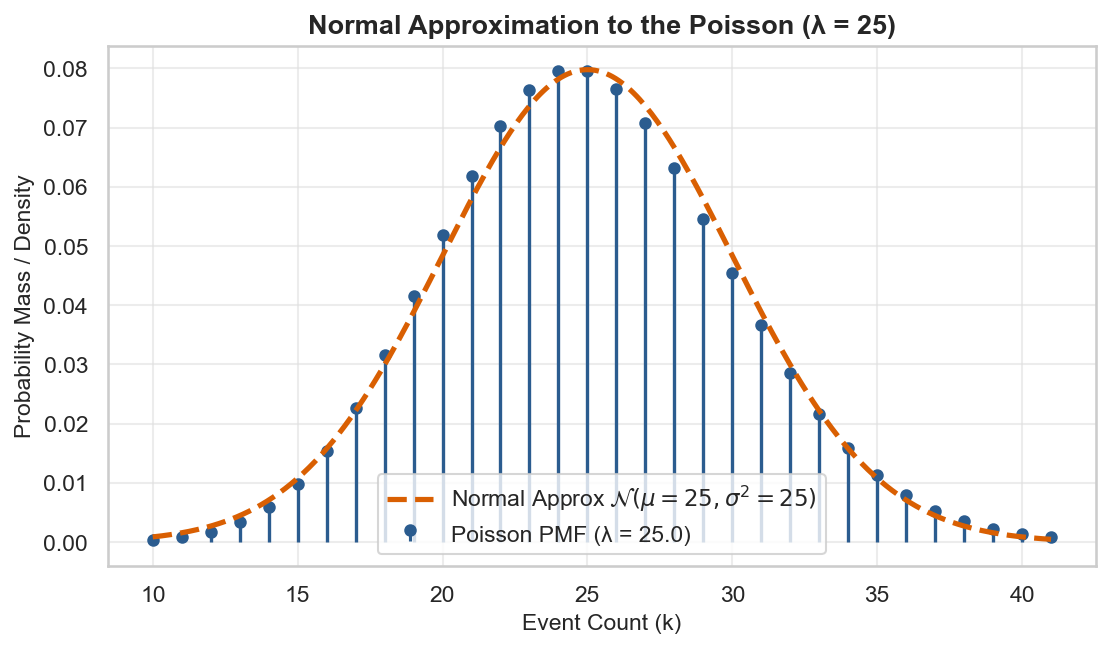

In [25]:
# Parameters for large lambda regime
lam_large = 25.0
k_vals = np.arange(10, 42)

# Theoretical Poisson PMF
poisson_pmf_large = stats.poisson.pmf(k_vals, lam_large)

# Continuous Normal approximation: N(mu = lam, sigma^2 = lam)
mu_norm = lam_large
sigma_norm = np.sqrt(lam_large)  # sqrt(25) = 5.0
x_smooth = np.linspace(10, 41, 300)
normal_pdf_large = stats.norm.pdf(x_smooth, loc=mu_norm, scale=sigma_norm)

fig, ax = plt.subplots(figsize=(8.5, 4.5))

# Plot discrete Poisson stems
markerline, stemlines, _ = ax.stem(
    k_vals, poisson_pmf_large, basefmt=" ", label=f"Poisson PMF (λ = {lam_large})"
)
plt.setp(markerline, color=PALETTE["primary"], markersize=5)
plt.setp(stemlines, color=PALETTE["primary"], linewidth=1.6)

# Overlay continuous Normal curve
ax.plot(
    x_smooth,
    normal_pdf_large,
    color=PALETTE["secondary"],
    linewidth=2.5,
    linestyle="--",
    label=fr"Normal Approx $\mathcal{{N}}(\mu={mu_norm:.0f}, \sigma^2={sigma_norm**2:.0f})$",
)

ax.set_title(
    f"Normal Approximation to the Poisson (λ = {lam_large:.0f})", weight="bold"
)
ax.set_xlabel("Event Count (k)")
ax.set_ylabel("Probability Mass / Density")
ax.legend(frameon=True)
ax.set_xticks(range(10, 42, 5))
plt.show()

### Summary Card: Poisson Distribution

| Property | Formulation |
| :--- | :--- |
| **Notation** | $X \sim \text{Poisson}(\lambda)$ |
| **Parameter** | $\lambda > 0$ (rate parameter, expected events per interval) |
| **Support** | $k \in \{0, 1, 2, 3, \dots\}$ (countably infinite) |
| **PMF** | $P(X = k) = \frac{\lambda^k e^{-\lambda}}{k!}$ |
| **CDF** | $F(k) = e^{-\lambda}\sum_{i=0}^{\lfloor k \rfloor} \frac{\lambda^i}{i!} = \frac{\Gamma(\lfloor k+1 \rfloor, \lambda)}{\lfloor k \rfloor!}$ |
| **Mean ($\mu$)** | $\lambda$ |
| **Variance ($\sigma^2$)** | $\lambda$ (Equidispersion: $\text{Var} = \mu$) |
| **Skewness ($\gamma_1$)** | $\frac{1}{\sqrt{\lambda}}$ |
| **Excess Kurtosis ($\gamma_2$)** | $\frac{1}{\lambda}$ |
| **MLE Estimator** | $\hat{\lambda} = \frac{1}{N}\sum_{i=1}^N k_i = \bar{k}$ |
| **Conjugate Prior** | Gamma distribution |
| **Key Use Cases** | Server requests per sec, call center arrivals, defect rates, emergency room visits |